In [71]:
import pandas as pd
import numpy as np

In [72]:
# load the dataset
dataset_df = pd.read_csv("taxi_dataset.csv", index_col="state")

print(dataset_df.shape)                             
print(dataset_df["best_action"].value_counts().sort_index())

(404, 5)
best_action
0    117
1    152
2     47
3     72
4     12
5      4
Name: count, dtype: int64


In [73]:
# preprocess the dataset (we have to remove the 4 states which says go south after the drop off , episodes has already ended)
dataset_df = dataset_df.drop([0, 85, 410, 475])   
print(dataset_df.shape)        

(400, 5)


In [74]:
X = dataset_df[["taxi_row", "taxi_col", "pass_idx", "dest_idx"]]
y = dataset_df["best_action"]

print(X.shape)   # (400, 4)  → 400 questions, 4 numbers each
print(y.shape)   # (400,)    → 400 answers

(400, 4)
(400,)


In [75]:
# one-hot encode for pass_idx and dest_idx
X_onehot = pd.get_dummies(X, columns=["pass_idx", "dest_idx"]).astype(int)

print(X_onehot)
print(X_onehot.shape) 
X_onehot.to_csv("taxi_dataset_one_hot_encode.csv")

       taxi_row  taxi_col  pass_idx_0  pass_idx_1  pass_idx_2  pass_idx_3  \
state                                                                       
1             0         0           1           0           0           0   
2             0         0           1           0           0           0   
3             0         0           1           0           0           0   
4             0         0           0           1           0           0   
6             0         0           0           1           0           0   
...         ...       ...         ...         ...         ...         ...   
494           4         4           0           0           0           1   
496           4         4           0           0           0           0   
497           4         4           0           0           0           0   
498           4         4           0           0           0           0   
499           4         4           0           0           0           0   

In [76]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_onehot, y,
    test_size=0.2,
    stratify=y,
    random_state=0
)

print(X_train.shape, X_test.shape)

(320, 11) (80, 11)


In [77]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

model = MLPClassifier(max_iter=1000, random_state=0)
model.fit(X_train, y_train)

train_accuracy = accuracy_score(y_train, model.predict(X_train))
test_accuracy = accuracy_score(y_test, model.predict(X_test))

print("Training accuracy:", train_accuracy)
print("Test accuracy    :", test_accuracy)

Training accuracy: 0.95
Test accuracy    : 0.65


/Users/yasandu/Desktop/taxi-driver/venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


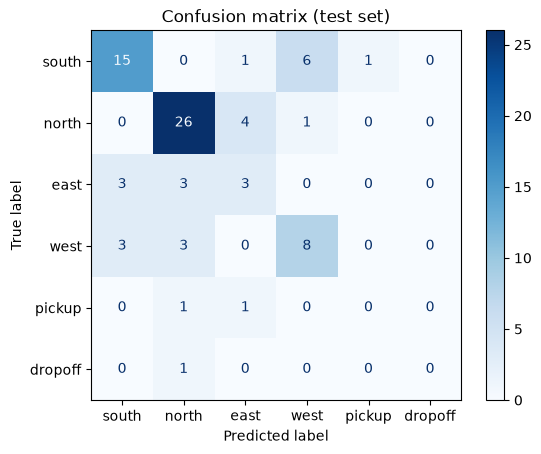

              precision    recall  f1-score   support

       south       0.71      0.65      0.68        23
       north       0.76      0.84      0.80        31
        east       0.33      0.33      0.33         9
        west       0.53      0.57      0.55        14
      pickup       0.00      0.00      0.00         2
     dropoff       0.00      0.00      0.00         1

    accuracy                           0.65        80
   macro avg       0.39      0.40      0.39        80
weighted avg       0.63      0.65      0.64        80

ROC-AUC (average over actions): 0.819231244165853
  south    AUC = 0.889
  north    AUC = 0.913
  east     AUC = 0.912
  west     AUC = 0.821
  pickup   AUC = 0.949
  dropoff  AUC = 0.430
RMSE (probabilities): 0.30411868479023296
RMSE (action numbers): 1.4361406616345072


In [78]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_auc_score, mean_squared_error)

action_names = ["south", "north", "east", "west", "pickup", "dropoff"]

y_pred = model.predict(X_test)          # the network's answer for each test question
y_prob = model.predict_proba(X_test)    # how confident it is in each of the 6 actions

# 1. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=range(6))
ConfusionMatrixDisplay(cm, display_labels=action_names).plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()

# 2. Precision, recall, F1 for each action
print(classification_report(y_test, y_pred, labels=range(6),
                            target_names=action_names, zero_division=0))

# 3. ROC-AUC
y_test_onehot = np.eye(6)[y_test]       # the true answers as yes/no columns
print("ROC-AUC (average over actions):",
      roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro"))
for i, name in enumerate(action_names):
    print(f"  {name:8s} AUC = {roc_auc_score(y_test_onehot[:, i], y_prob[:, i]):.3f}")

# 4. RMSE (two versions)
print("RMSE (probabilities):", np.sqrt(mean_squared_error(y_test_onehot, y_prob)))
print("RMSE (action numbers):", np.sqrt(mean_squared_error(y_test, y_pred)))

   split  mean_accuracy       std  lowest   highest
0  60/40       0.706250  0.020540  0.6875  0.731250
1  70/30       0.708333  0.030277  0.6500  0.733333
2  80/20       0.760000  0.033912  0.7250  0.812500
3  90/10       0.775000  0.050000  0.7000  0.850000


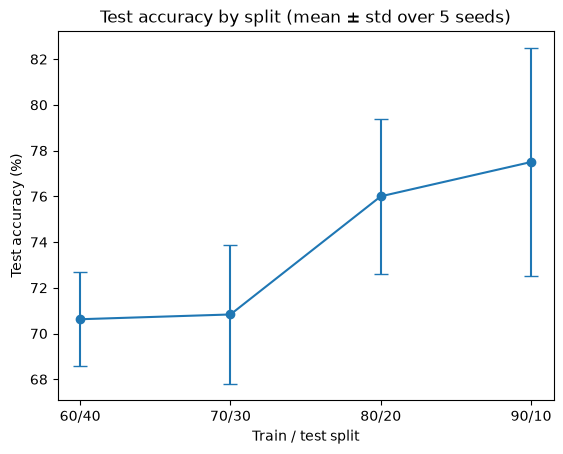

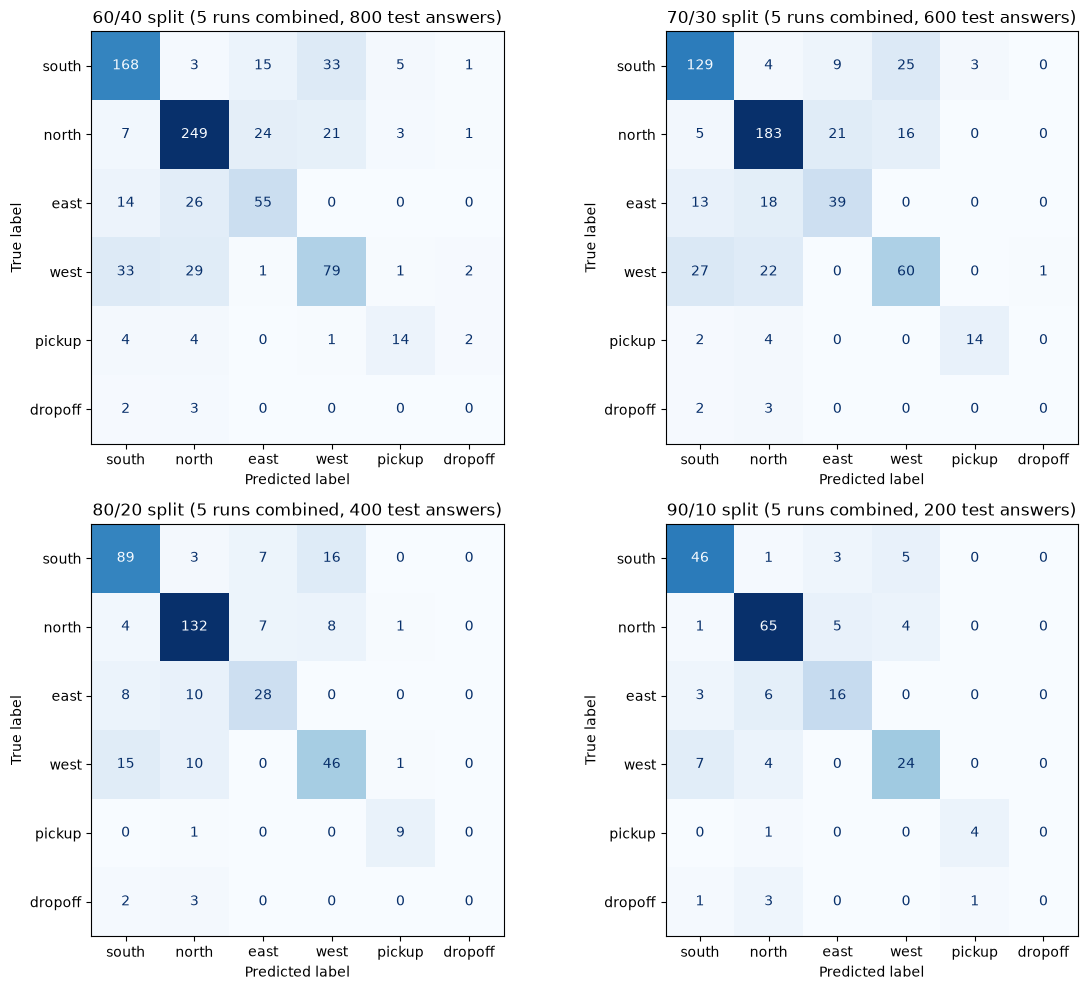

In [79]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

best_settings = dict(hidden_layer_sizes=(200, 100), activation="relu",
                     solver="lbfgs", alpha=0.01, max_iter=3000)

action_names = ["south", "north", "east", "west", "pickup", "dropoff"]

split_results = []
split_cms = {}                                   # one combined confusion matrix per split

for test_size in [0.4, 0.3, 0.2, 0.1]:
    scores = []
    total_cm = np.zeros((6, 6), dtype=int)       # empty 6x6 matrix for this split

    for seed in range(5):                        # 5 different shuffles
        X_train, X_test, y_train, y_test = train_test_split(
            X_onehot, y, test_size=test_size, stratify=y, random_state=seed)

        model = MLPClassifier(random_state=0, **best_settings)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        scores.append(accuracy_score(y_test, y_pred))
        total_cm += confusion_matrix(y_test, y_pred, labels=range(6))   # add this run's matrix

    split_name = f"{round((1 - test_size) * 100)}/{round(test_size * 100)}"
    split_cms[split_name] = total_cm
    split_results.append({
        "split": split_name,
        "mean_accuracy": np.mean(scores),
        "std": np.std(scores),
        "lowest": min(scores),
        "highest": max(scores),
    })

split_df = pd.DataFrame(split_results)
print(split_df)

# chart 1: accuracy by split
plt.errorbar(split_df["split"], split_df["mean_accuracy"] * 100,
             yerr=split_df["std"] * 100, marker="o", capsize=5)
plt.xlabel("Train / test split")
plt.ylabel("Test accuracy (%)")
plt.title("Test accuracy by split (mean ± std over 5 seeds)")
plt.show()

# chart 2: confusion matrix for each split (5 runs added together)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (split_name, cm) in zip(axes.flat, split_cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=action_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{split_name} split (5 runs combined, {cm.sum()} test answers)")
plt.tight_layout()
plt.show()